# Phase mapping of a 4D-STEM scan

A sample often holds more than one crystal phase: precipitates in an alloy, an oxide on a metal,
two phases of a steel. In a 4D-STEM scan each point records a diffraction pattern, and if each
pattern is assigned to the phase it came from, the scan becomes a **phase map**: where each phase
is, and how much of the area it covers. This notebook makes one with pyEMAPS, step by step, from a
synthetic scan of aluminium and copper grains whose phases are known, so you can see how well the
map recovers them. It follows the *al_cu_phasemap.py* sample, one step per cell.

You'll:

1. generate a database of simulated diffraction patterns for each phase;
2. make a scan of aluminium and copper grains, and see why their patterns are hard to tell apart;
3. map the scan's phases, and read the map and its confidence;
4. see which score decides, and why;
5. compare the map with the true phases, and save it.

**How it works.** `StackImage.mapPhases` indexes every pattern against each phase's database, as
`mapOrientation` indexes it against one (see the [orientation mapping notebook](al_orientmap.ipynb)).
emaps then scores each phase for each pattern and decides which one it belongs to.

**Experimental.** Phase mapping is new in pyEMAPS. It finds the right phases on simulated scans
like this one, but it hasn't yet been tested on measured data. Its parameters, defaults and
results may change in later releases.

**A licensed feature.** It needs an activated pyEMAPS license. `pyemaps -l trial`, run in a
terminal with an internet connection, activates a free 7-day trial; for a full license, contact
support@emlabsoftware.com. Step 1 checks it.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment. Mapping the scan takes under a minute.

The [phase maps section](https://emlab-solutions.github.io/pyemaps/user_guide/indexing.html#phase-maps)
of the indexing guide covers the same ground.

## Step 1: Import pyEMAPS and check the license

`StackImage` holds experimental images and runs the 4D-STEM analyses, and `PhaseMap` holds a phase
map. The *al_cu_phasemap.py* sample that comes with pyEMAPS has the functions that draw the
synthetic scan; the notebook imports them as `demo`.

In [1]:
import os
import sys
import tempfile
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt

import pyemaps
from pyemaps import EMC, Crystal, StackImage, PhaseMap, write_im3, stem4d

print('pyEMAPS', version('pyemaps'))
if stem4d.check_license_once() == stem4d.LICENSE_ACTIVE:
    print('License: active')
else:
    print('No active license: run "pyemaps -l trial" in a terminal for a 7-day trial, '
          'or contact support@emlabsoftware.com.')

# The sample scripts that come with pyEMAPS, for the synthetic scan.
sys.path.insert(0, os.path.join(os.path.dirname(pyemaps.__file__), 'samples'))
import al_cu_phasemap as demo

pyEMAPS 0.0.0.dev0
License: active


## Step 2: Read the crystals and generate a database for each phase

The two phases' crystal structures are refined structures from the
[Crystallography Open Database](https://www.crystallography.net) (COD), with their thermal
factors: aluminium from entry 4004108 and copper from entry 7101269. Their CIF files come with
the sample, and `demo.load_phases` reads them with `Crystal.from_cif`.

`generateDPDB` then simulates kinematic diffraction patterns of each crystal over a range of
orientations and saves them to a database file. Phase mapping needs one database per phase,
made the same way.

In [2]:
crystals = demo.load_phases()
databases = {}
for name, crystal in crystals.items():
    ret, databases[name] = crystal.generateDPDB(emc=EMC(zone=(0, 0, 1)), xa=(2, 0, 0), res=200)
    print(f'{name}: {demo.PHASES[name]}, lattice constant {float(crystal.cell.a)} Å, '
          f'database {os.path.basename(databases[name])}')


Info: closest matching space group information found in pyemaps: [(225, 1)]

Info: closest matching space group information found in pyemaps: [(225, 1)]


*******************************************************************************


* The diffraction pattern database for Aluminium has been generated successfully
* and saved in:
* C:\pyemaps_data\dpdb\Aluminium-20261126151239.bin
*******************************************************************************
Aluminium: Al_COD_4004108.cif, lattice constant 4.0494 Å, database Aluminium-20261126151239.bin
*******************************************************************************
* The diffraction pattern database for Copper has been generated successfully
* and saved in:
* C:\pyemaps_data\dpdb\Copper-20261126151241.bin
*******************************************************************************
Copper: Cu_COD_7101269.cif, lattice constant 3.61447 Å, database Copper-20261126151241.bin


## Step 3: Make a synthetic scan

The scan is 14 x 14 points, with five grains. Each grain has a phase, a zone axis $[uvw]$ along
the beam, an in-plane rotation, and a seed point; every scan point belongs to the grain of the
nearest seed.

In [3]:
for phase, zone, angle, seed in demo.GRAINS:
    print(f'{phase:9s} zone axis {list(zone)}, turned {angle:5.1f} degrees, seed at {seed}')

rng = np.random.default_rng(1)
patterns, truth = demo.make_scan(rng, crystals)
names = list(demo.PHASES)
print('patterns:', patterns.shape, '(scan points, rows, columns)')
print('true phases:', {n: int(np.count_nonzero(truth == i)) for i, n in enumerate(names)})

Aluminium zone axis [1, 1, 1], turned  17.0 degrees, seed at (2, 3)
Copper    zone axis [1, 1, 2], turned 141.0 degrees, seed at (3, 10)
Copper    zone axis [0, 1, 1], turned 233.0 degrees, seed at (9, 2)
Aluminium zone axis [1, 1, 4], turned 302.0 degrees, seed at (10, 10)
Copper    zone axis [1, 1, 1], turned  64.0 degrees, seed at (7, 7)


patterns: (196, 200, 200) (scan points, rows, columns)
true phases: {'Aluminium': 85, 'Copper': 111}


## Step 4: Why the phases look alike

Aluminium and copper are both face-centred cubic (FCC), with lattice constants 4.049 and 3.614 Å.
Their diffraction patterns have the same reflections, at the same angles to each other; only the
scale differs, by 12%. Below, a [111] pattern of each: the same hexagon of spots, the copper one
larger.

A reflection $(hkl)$ of a cubic crystal lies at $|\mathbf g| = \sqrt{h^2+k^2+l^2}/a$ from the
pattern's centre, and at $cc\,|\mathbf g|$ pixels on the detector, with the camera constant $cc$.
The table lists the first spacings of each phase in pixels: they never coincide.

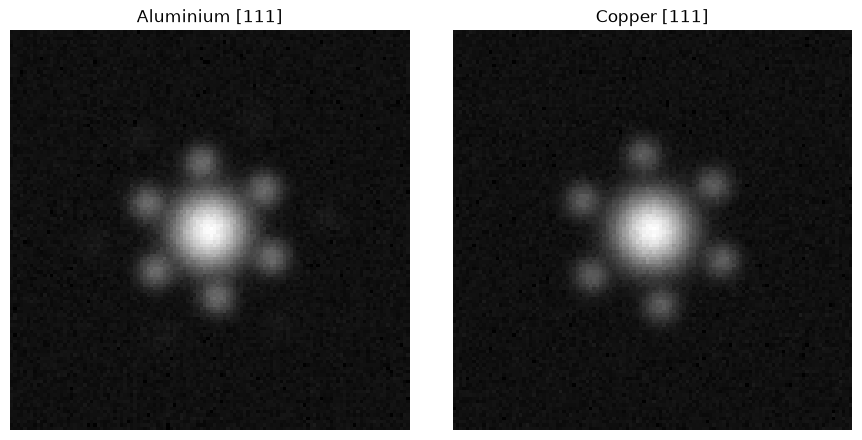

reflection   Aluminium   Copper   (pixels from the centre)
(1, 1, 1)        12.4      13.9
(2, 0, 0)        14.3      16.0
(2, 2, 0)        20.3      22.7
(3, 1, 1)        23.8      26.6
(2, 2, 2)        24.8      27.8


In [4]:
lattice = {name: float(c.cell.a) for name, c in crystals.items()}
al_111 = demo.spot_pattern(demo.zone_orientation((1, 1, 1), 0.0), lattice['Aluminium'], rng)
cu_111 = demo.spot_pattern(demo.zone_orientation((1, 1, 1), 0.0), lattice['Copper'], rng)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
for ax, img, title in zip(axes, (al_111, cu_111), ('Aluminium [111]', 'Copper [111]')):
    ax.imshow(np.sqrt(img[40:160, 40:160]), cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

print('reflection   Aluminium   Copper   (pixels from the centre)')
for hkl in [(1, 1, 1), (2, 0, 0), (2, 2, 0), (3, 1, 1), (2, 2, 2)]:
    r = [demo.CC * np.sqrt(sum(i * i for i in hkl)) / a for a in lattice.values()]
    print(f'{str(hkl):11s} {r[0]:9.1f} {r[1]:9.1f}')

That is the trouble for indexing. It matches the peaks' angles and the ratios of their
distances, which is what makes it robust to small calibration errors, but it means aluminium's
database also indexes copper's patterns, and the other way round. The spacings themselves, with a
known camera constant, tell the phases apart.

## Step 5: Map the phases

`mapPhases` takes the databases by name, and the same settings as `mapOrientation`. It indexes
every pattern against each database in turn, so it takes as long as one orientation map per
phase, and returns a `PhaseMap`.

In [5]:
with tempfile.TemporaryDirectory() as tmp:
    scan_file = os.path.join(tmp, 'al_cu_scan.im3')
    write_im3(scan_file, patterns)
    pmap = StackImage(scan_file).mapPhases(databases, cc=demo.CC, sigma=demo.SIGMA,
                                           img_center=demo.CENTER, scan_shape=demo.SCAN,
                                           progress=False)
print(pmap)

Diffraction Database loaded successfully.
Dimension of stereo projection map: width =76, height=85


Diffraction Database loaded successfully.
Dimension of stereo projection map: width =76, height=85


PhaseMap(14 x 14 patterns: Aluminium 44%, Copper 56%; 2 ambiguous)


## Step 6: Read the map

`pmap.show()` colours each point by its phase, with each phase's share of the decided points.
A point whose best phase doesn't lead the second clearly is **ambiguous** and grey; a point with
no peaks to score has no phase and is black.

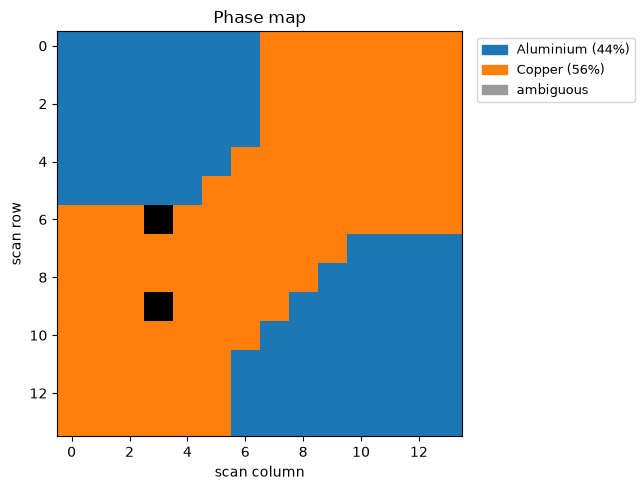

In [6]:
pmap.show();

The **confidence** is how far the best phase leads the second. Below `min_confidence` (0.2 by
default) the point is ambiguous.

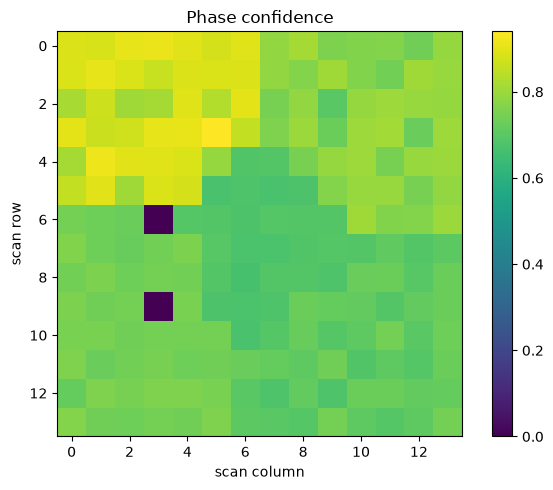

In [7]:
pmap.show('confidence');

## Step 7: Which score decides

emaps scores each phase for each point, from 0 to 1:

- **spacing**: how well the peaks' distances from the centre match the phase's reflection
  spacings, with the camera constant. It needs no orientation;
- **explained**: the share of the peaks the indexing matched to the phase's database;
- **predicted**: the share of the matched database pattern's predicted intensity that has a peak
  where it's predicted.

The spacing score is high for each phase only where that phase is:

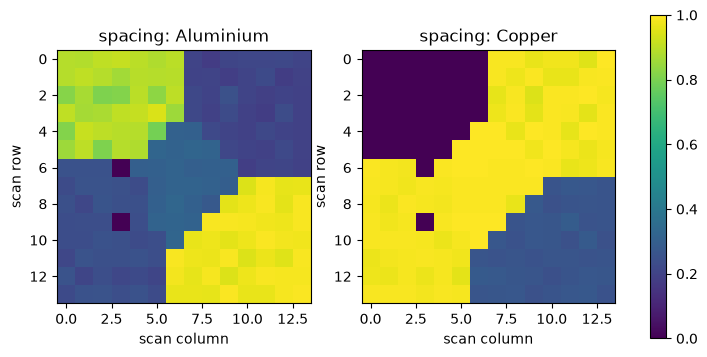

In [8]:
pmap.show('spacing');

The indexing's **explained** score, by contrast, hardly tells the phases apart: each database
explains most of the other phase's peaks too, and in the lower-left copper grain the two scores
are about equal.

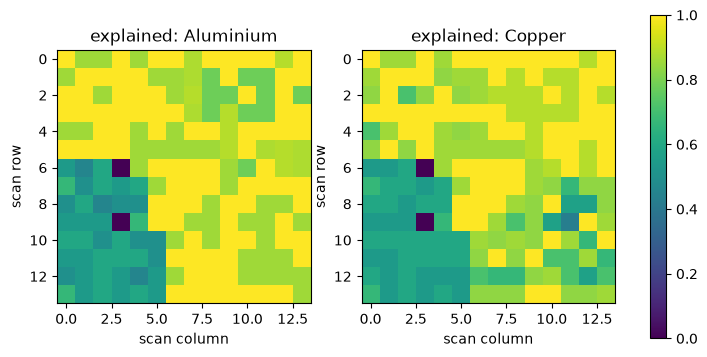

In [9]:
pmap.show('explained');

So by default only the spacing score decides (`orientation_weight=0`). On synthetic scans of
aluminium with copper and with silicon it decided 78 to 98% of the points, all correctly, while
adding the indexing's scores brought some errors back. For phases whose spacings coincide, which
the spacing score can't tell apart, raise `orientation_weight`.

## Step 8: Compare with the truth

The scan was made from known phases, so the map can be checked point by point:

In [10]:
decided = pmap.decided()
right = pmap.phase[decided] == truth[decided]
print(f'{np.count_nonzero(decided)} of {truth.size} points decided; '
      f'{np.count_nonzero(right)} of them right')
print('each phase\'s share of the decided points:',
      {k: f'{100 * v:.0f}%' for k, v in pmap.fractions().items()})

194 of 196 points decided; 194 of them right
each phase's share of the decided points: {'Aluminium': '44%', 'Copper': '56%'}


Each phase also has its own orientation map, `pmap.maps`, and `pmap.show('ipf')` colours each
point by its orientation from its own phase's map: within a grain, one colour.

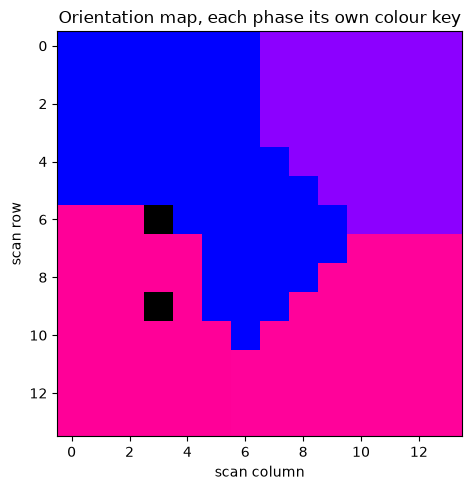

In [11]:
pmap.show('ipf');

## Step 9: Save the map

`save` writes the map, with each phase's orientation map, to a NumPy *.npz* file, and
`PhaseMap.load` reads it back.

In [12]:
pmap.save('al_cu_phase_map.npz')
again = PhaseMap.load('al_cu_phase_map.npz')
print(again)
print('same phases:', np.array_equal(again.phase, pmap.phase))

PhaseMap(14 x 14 patterns: Aluminium 44%, Copper 56%; 2 ambiguous)
same phases: True


## Try it yourself

1. **A miscalibrated camera constant.** Map the scan again with `cc=demo.CC * 1.03`. How many
   points stay decided? The spacing score is only as good as the calibration: with `spacing_tol`
   (1 pixel by default) larger, it forgives more, and tells close phases apart less well.
2. **Phases too close to tell apart.** Add gold, `Crystal.from_builtin('Gold_FCC')`, also FCC,
   with a lattice constant of 4.08 Å, 0.7% from aluminium's 4.05 Å. Make its database and map
   the scan with all three. What happens to the aluminium grains?
3. **The indexing's scores.** Map with `orientation_weight=1.0` and compare with Step 8.
4. **Your own grains.** Edit `demo.GRAINS` (phase, zone axis, rotation, seed point) and rerun
   from Step 3. Which zone axes give too few peaks to decide?

## Next

- The orientation mapping notebook, [al_orientmap.ipynb](al_orientmap.ipynb), which maps one
  phase's orientations and compares them with the truth.
- The pattern indexing notebook, [al_ediom.ipynb](al_ediom.ipynb), which indexes one
  experimental pattern and checks the result by hand.
- The [phase maps section](https://emlab-solutions.github.io/pyemaps/user_guide/indexing.html#phase-maps)
  of the indexing guide, and the reference for
  [`mapPhases`](https://emlab-solutions.github.io/pyemaps/api/images.html#pyemaps.stackimg.StackImage.mapPhases).

## Further reading

J. C. H. Spence and J. M. Zuo, *Electron Microdiffraction* (Plenum, New York, 1992),
[doi:10.1007/978-1-4899-2353-0](https://doi.org/10.1007/978-1-4899-2353-0):

- chapter 2, *The Geometry of CBED Patterns*, for reflection spacings and indexing in Steps 4
  and 7.

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3):

- chapter 3, *The Geometry of Electron Diffraction Patterns*, for the camera constant and the
  spacings in Step 4.